# Counterparty credit risk on a 10y interest rate swap

**Polimi Bank, 15 February 2008.** The rates desk has just entered a vanilla 10y payer
interest rate swap on a EUR 100m notional. The floating leg pays 3M Euribor
(ACT/360, modified following), the fixed leg is annual 30E/360. Risk management
measures the counterparty credit risk of the position with a Monte Carlo
simulation of the term structure under the Hull-White extended Vasicek model.

The notebook answers, in order:

1. the affine representation of the simulated discount curve, and its simulation;
2. the mark-to-market of the swap at every simulation date and in every scenario;
3. the expected positive exposure (EPE) profile;
4. the 95% potential future exposure (PFE) profile;
5. the Peak-PFE;
6. the same metrics under three risk mitigants — a mandatory 3.5y break clause, a
   netting agreement with a second trade, and a one-sided CSA with annual margin calls;
7. the resulting CVA and its sensitivities.

All the quantitative logic lives in the `ccr` package; this notebook orchestrates it
and comments the results.

**Data.** The market quotes are not redistributed with the repository. When the CSV files
are present in `data/`, the curve is bootstrapped from them; otherwise the notebook falls
back automatically on a Svensson curve fitted to the same data, and every cell still runs.
The fallback reproduces the published Peak-PFE within 1% and the CVA within about 2%.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from ccr import (
    CreditParameters,
    CSAParameters,
    HullWhiteParameters,
    InterestRateSwap,
    SimulationConfig,
    SwapType,
    affine_coefficients,
    bootstrap,
    compute_cva,
    cva_sensitivities,
    load_curve,
    peak_pfe,
    run_simulation,
    simulate_state_paths,
    simulated_discount_factors,
)
from ccr.dates import MODEL_BASIS, business_date_offset, year_fraction_act

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
MILLION = 1e6

## 1. Market data and discount curve

The curve is bootstrapped from deposits, the futures strip and par swap rates. Deposits
are used up to the settlement of the first future, futures up to the 2y swap pillar, and
swap quotes from 2y onwards — so the 1y point is implied by the futures strip and carries
the futures/swap basis of February 2008 rather than the 1y swap quote.

Without the data files, the Svensson fallback is used: within 2.5 bp of the bootstrapped
curve beyond two years, but it smooths out the money-market structure below two years.

Curve source:    market data (bootstrap)
Today:           15 Feb 2008
Settlement:      19 Feb 2008
Curve pillars:   59 (Feb 2008 to Feb 2058)


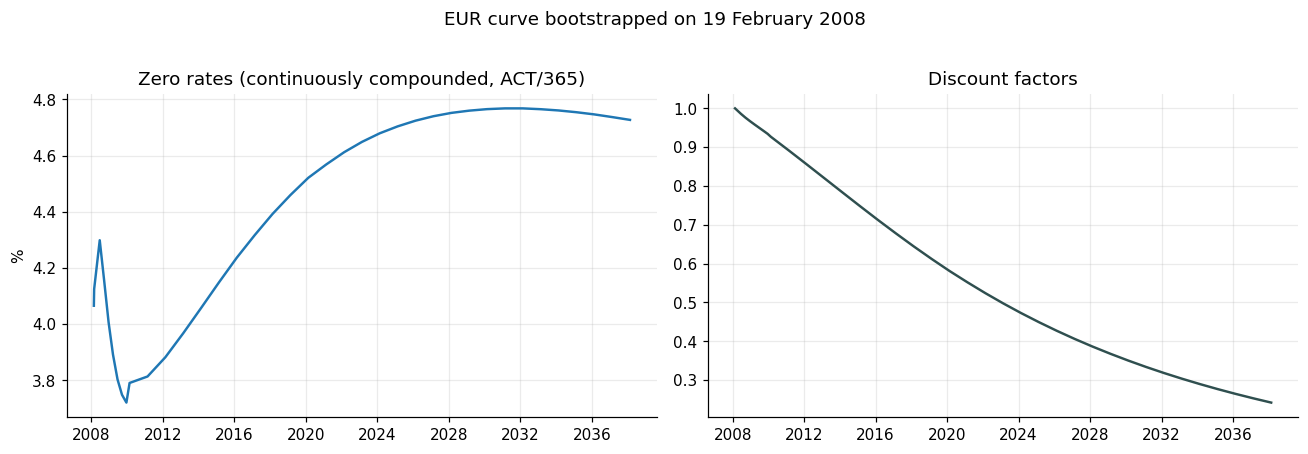

In [2]:
source = load_curve(ROOT / "data")
curve = source.curve
settlement_date = source.settlement_date

print(f"Curve source:    {source.name}")
print(f"Today:           {source.today:%d %b %Y}")
print(f"Settlement:      {settlement_date:%d %b %Y}")
print(f"Curve pillars:   {len(curve.pillar_dates)} "
      f"({curve.pillar_dates[1]:%b %Y} to {curve.pillar_dates[-1]:%b %Y})")

horizon = settlement_date + pd.DateOffset(years=30)
zero_rates = curve.zero_rate_series().loc[:horizon]
pillars = curve.pillar_dates <= horizon
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(zero_rates.index, zero_rates.values * 100, lw=1.6)
axes[0].set_title("Zero rates (continuously compounded, ACT/365)")
axes[0].set_ylabel("%")
axes[1].plot(curve.pillar_dates[pillars], curve.discount_factors[pillars], lw=1.6,
             color="darkslategray")
axes[1].set_title("Discount factors")
fig.suptitle("EUR curve bootstrapped on 19 February 2008", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "curve.png", bbox_inches="tight")
plt.show()

### Repricing check

*(Market data only.)* The bootstrap is only trustworthy if the curve reprices the instruments it was built
from. Every swap from 2y onwards is recovered to machine precision; the 1y point sits
about 12 bp below the swap quote, which is the futures/swap basis and not an error.

In [3]:
from ccr import par_swap_rate

if source.is_synthetic:
    print("Fallback curve in use: there are no market quotes to reprice.")
else:
    market = source.market
    mid_quotes = market.swaps[["BID", "ASK"]].mean(axis=1)
    repricing = pd.DataFrame({
        "market (%)": mid_quotes * 100,
        "model (%)": [
            par_swap_rate([d for d in market.swaps.index if d <= maturity], curve,
                          settlement_date) * 100
            for maturity in market.swaps.index
        ],
    })
    repricing["error (bp)"] = (repricing["model (%)"] - repricing["market (%)"]) * 100
    display(repricing.head(6).style.format("{:.4f}"))
    print(f"Max |error| from the 2y pillar onwards: "
          f"{repricing['error (bp)'].iloc[1:].abs().max():.2e} bp")

,market (%),model (%),error (bp)
Swaps,,,
2009-02-19 00:00:00,4.1300,4.0140,-11.5997
2010-02-19 00:00:00,3.8715,3.8715,0.0000
2011-02-21 00:00:00,3.8920,3.8920,0.0000
2012-02-20 00:00:00,3.9580,3.9580,0.0000
2013-02-19 00:00:00,4.0420,4.0420,-0.0000
2014-02-19 00:00:00,4.1270,4.1270,-0.0000


Max |error| from the 2y pillar onwards: 4.00e-13 bp


## 2. Hull-White model and the affine trick

Write the short rate as $r_t = \varphi(t) + x_t$, where $\varphi$ is the deterministic
shift that fits the initial curve exactly and $x$ is a driftless Ornstein-Uhlenbeck
process, $dx_t = -a\,x_t\,dt + \sigma\,dW_t$, $x_0 = 0$.

Rather than re-integrating $\varphi$ in each scenario, the whole simulated curve is
recovered from the single state variable $x_s$:

$$B(s,\tau) = A(s,\tau)\,e^{-x_s C(s,\tau)}, \qquad
A(s,\tau) = \frac{B(0,\tau)}{B(0,s)}\,e^{-\frac12\int_0^s[\sigma(u,\tau)^2-\sigma(u,s)^2]du},
\qquad C(s,\tau) = \frac{1-e^{-a(\tau-s)}}{a}$$

with $\sigma(u,x) = \sigma\,(1-e^{-a(x-u)})/a$. The package evaluates the integral in
closed form through $V(\tau) = \operatorname{Var}\!\left[\int_0^\tau x_u\,du\right]$,
which gives $-\tfrac12 I(s,\tau) = \tfrac12[V(s) - V(\tau) + V(\tau-s)]$ — the classical
Hull-White expression. The cell below checks the closed form against a direct numerical
quadrature of the integral, which is also what pins the **sign** of the exponent: the
convexity correction pushes $A$ *below* the forward discount factor.

In [4]:
from scipy.integrate import quad

hw = HullWhiteParameters(mean_reversion=0.0205, sigma=0.0094)
config = SimulationConfig(n_scenarios=250_000, horizon_years=10, steps_per_year=4)

from ccr import simulation_grid
grid = simulation_grid(settlement_date, config)
print(f"{len(grid)} simulation dates, {grid[0]:%d %b %Y} to {grid[-1]:%d %b %Y}")

valuation_date = grid[19]
A, C = affine_coefficients(valuation_date, grid, hw, curve)

def numerical_exponent(tau_s, tau_T, params):
    a, sigma = params.mean_reversion, params.sigma
    integrand = lambda u: ((sigma / a * (1 - np.exp(-a * (tau_T - u)))) ** 2
                           - (sigma / a * (1 - np.exp(-a * (tau_s - u)))) ** 2)
    return -0.5 * quad(integrand, 0.0, tau_s)[0]

tau_s = year_fraction_act(curve.reference_date, valuation_date, MODEL_BASIS)
check = []
for j in range(20, len(grid), 4):
    tau_T = year_fraction_act(curve.reference_date, grid[j], MODEL_BASIS)
    forward = curve.discount(grid[j]) / curve.discount(valuation_date)
    check.append({
        "tau": round(tau_T, 2),
        "A closed form": A[j],
        "A quadrature": forward * np.exp(numerical_exponent(tau_s, tau_T, hw)),
        "forward B(0,T)/B(0,s)": forward,
    })
check = pd.DataFrame(check).set_index("tau")
check["difference (bp)"] = (check["A closed form"] / check["A quadrature"] - 1) * 1e4
display(check.style.format({"A closed form": "{:.8f}", "A quadrature": "{:.8f}",
                            "forward B(0,T)/B(0,s)": "{:.8f}", "difference (bp)": "{:.2e}"}))

40 simulation dates, 19 May 2008 to 19 Feb 2018


,A closed form,A quadrature,"forward B(0,T)/B(0,s)",difference (bp)
tau,,,,
5.250000,0.98885793,0.98885793,0.98911310,-7.77e-12
6.250000,0.94376071,0.94376071,0.94520527,-5.55e-12
7.250000,0.89865570,0.89865570,0.90149470,1.55e-11
8.250000,0.85405912,0.85405912,0.85843688,-1.11e-12
9.250000,0.81068297,0.81068297,0.81668240,4.44e-12


### Simulated curves

The state variable is simulated with its exact transition law — $x_{t+\Delta}\mid x_t$ is
Gaussian with mean $x_t e^{-a\Delta}$ and variance $\frac{\sigma^2}{2a}(1-e^{-2a\Delta})$ —
so the scheme carries no discretisation bias. Below, the distribution of the curve seen
from five years out.

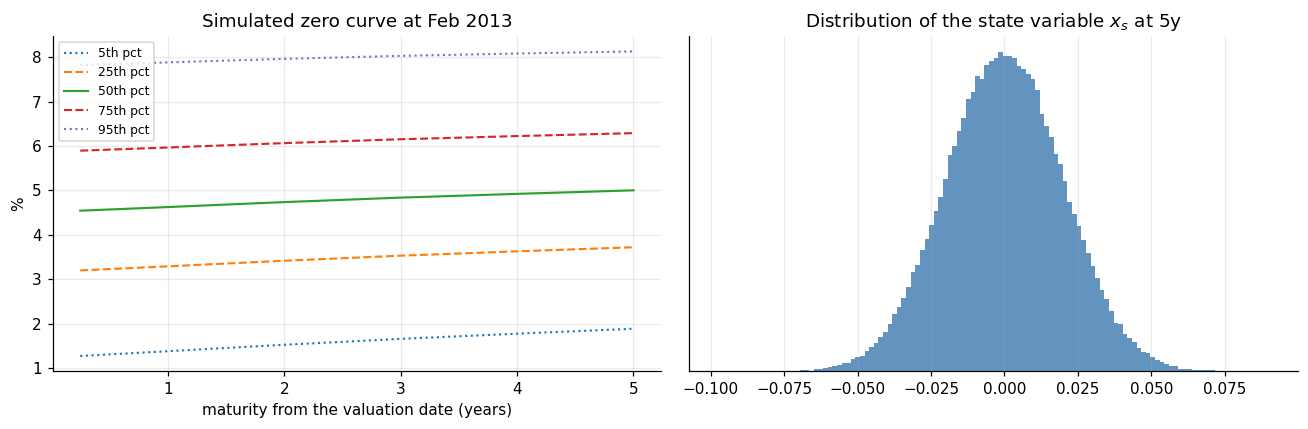

In [5]:
state_paths = simulate_state_paths(grid, settlement_date, hw,
                                   config.n_scenarios, seed=config.seed)
dfs_at_5y = simulated_discount_factors(state_paths[:, 19], valuation_date, grid, hw, curve)

future = grid > valuation_date
taus = np.array([year_fraction_act(valuation_date, d, MODEL_BASIS) for d in grid])[future]
zero_paths = -np.log(dfs_at_5y[:, future]) / taus

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for q, style in [(5, ":"), (25, "--"), (50, "-"), (75, "--"), (95, ":")]:
    axes[0].plot(taus, np.percentile(zero_paths, q, axis=0) * 100, style,
                 lw=1.4, label=f"{q}th pct")
axes[0].set_title(f"Simulated zero curve at {valuation_date:%b %Y}")
axes[0].set_xlabel("maturity from the valuation date (years)")
axes[0].set_ylabel("%")
axes[0].legend(fontsize=8)

axes[1].hist(state_paths[:, 19], bins=120, color="steelblue", alpha=0.85)
axes[1].set_title("Distribution of the state variable $x_s$ at 5y")
axes[1].set_yticks([])
fig.tight_layout()
fig.savefig(FIGURES / "simulated_curves.png", bbox_inches="tight")
plt.show()

## 3. The portfolio

Two trades, both struck at par on the bootstrapped curve:

| | notional | direction | maturity | fixed leg |
|---|---|---|---|---|
| Swap 1 (the position under study) | EUR 100m | payer | 10y | annual, 30E/360 |
| Swap 2 (netting set, scenario 6b) | EUR 150m | receiver | 5y | quarterly, 30E/360 |

A swap struck at its par rate is worth exactly zero at inception — the check below is the
one that catches a fixed leg built without its accrual factors, a mistake that is
invisible on an annual leg ($\delta \approx 1$) and multiplies a quarterly leg by four.

In [6]:
swap = InterestRateSwap.at_par(settlement_date, maturity_years=10,
                               fixed_frequency=1, notional=100e6,
                               swap_type=SwapType.PAYER, curve=curve)
swap_2 = InterestRateSwap.at_par(settlement_date, maturity_years=5,
                                 fixed_frequency=4, notional=150e6,
                                 swap_type=SwapType.RECEIVER, curve=curve)

for name, trade in [("Swap 1 (10y payer)", swap), ("Swap 2 (5y receiver)", swap_2)]:
    print(f"{name:24s} par rate = {trade.fixed_rate * 100:.4f}%   "
          f"mean accrual = {trade.accruals.mean():.4f}   "
          f"MtM at inception = {trade.mtm(curve):,.6f} EUR")

Swap 1 (10y payer)       par rate = 4.4340%   mean accrual = 1.0000   MtM at inception = 0.000000 EUR
Swap 2 (5y receiver)     par rate = 3.9816%   mean accrual = 0.2500   MtM at inception = -0.000000 EUR


## 4. Exposure simulation

One pass over the simulation grid produces, for every scenario and every mitigant, the
mark-to-market, then the exposure. All mitigants share the same simulated paths, so any
difference between them is contractual and not Monte Carlo noise.

* **base** — the 10y swap on its own, no mitigant;
* **break** — mandatory break at 3.5y: the trade is terminated at its mark-to-market, so
  the exposure drops to zero afterwards;
* **swap_2** — the 5y receiver on its own;
* **no_netting** — the two trades as separate netting sets, i.e. the sum of the positive parts;
* **netting** — the two trades in a single netting set, i.e. the positive part of the sum;
* **csa** — the 10y swap under a one-sided CSA with annual margin calls.

The CSA is calibrated as the case study requires: the bank never posts collateral
(infinite threshold, zero cap on its side) while the counterparty covers its exposure in
full (zero threshold, zero minimum transfer amount, no cap). Collateral is remunerated at
the shortest zero rate of the curve.

In [7]:
break_date = business_date_offset(settlement_date, year_offset=3, month_offset=6)
csa = CSAParameters.counterparty_fully_collateralised()

print(f"Mandatory break: {break_date:%d %b %Y}  (on the simulation grid: "
      f"{break_date in grid})")

results = run_simulation(
    curve=curve,
    settlement_date=settlement_date,
    swap=swap,
    swap_netting=swap_2,
    break_date=break_date,
    csa=csa,
    hw_params=hw,
    config=config,
)
print(f"{config.n_scenarios:,} scenarios simulated on {len(results.grid)} dates.")

Mandatory break: 19 Aug 2011  (on the simulation grid: True)


250,000 scenarios simulated on 40 dates.


### EPE and PFE of the uncollateralised swap (questions 3 to 5)

The profile of a par swap is the product of two opposing forces: diffusion widens the
distribution of future rates, while amortisation shortens the remaining annuity. The
exposure therefore peaks in the first third of the life of the trade and decays to zero
at maturity.

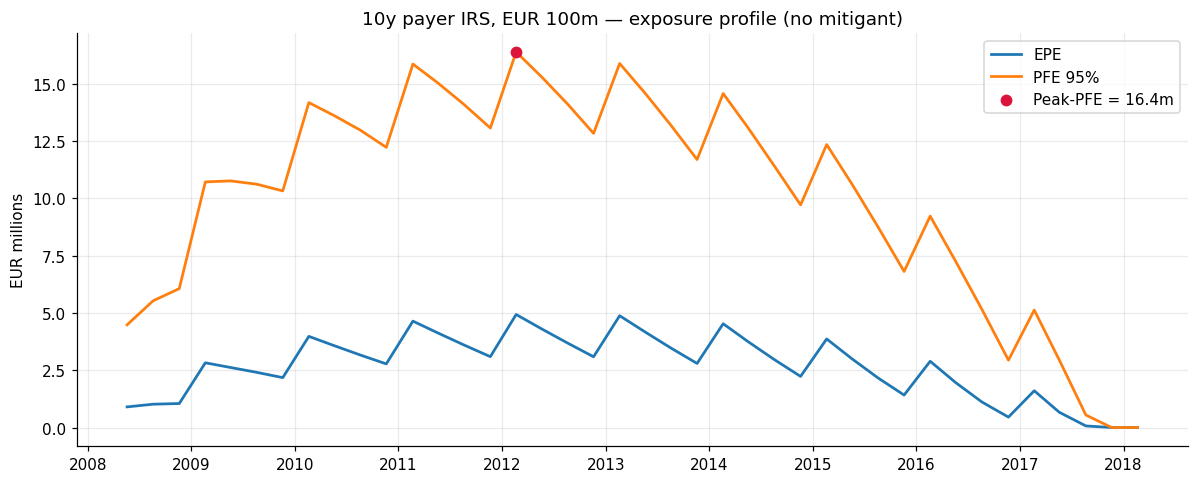

Peak-PFE       :     16,387,755 EUR  on 20 Feb 2012
Max EPE        :      4,932,168 EUR
EPE at maturity:              0 EUR


In [8]:
peaks = peak_pfe(results.pfe)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(results.grid, results.epe["base"] / MILLION, lw=1.8, label="EPE")
ax.plot(results.grid, results.pfe["base"] / MILLION, lw=1.8, label="PFE 95%")
ax.scatter([peaks.loc["base", "date"]], [peaks.loc["base", "peak_pfe"] / MILLION],
           zorder=5, color="crimson", s=45,
           label=f"Peak-PFE = {peaks.loc['base', 'peak_pfe'] / MILLION:.1f}m")
ax.set_title("10y payer IRS, EUR 100m — exposure profile (no mitigant)")
ax.set_ylabel("EUR millions")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "exposure_base.png", bbox_inches="tight")
plt.show()

print(f"Peak-PFE       : {peaks.loc['base', 'peak_pfe']:>14,.0f} EUR  "
      f"on {peaks.loc['base', 'date']:%d %b %Y}")
print(f"Max EPE        : {results.epe['base'].max():>14,.0f} EUR")
print(f"EPE at maturity: {results.epe['base'].iloc[-1]:>14,.0f} EUR")

### Risk mitigants (question 6)

Three independent arrangements, each compared with the uncollateralised position.

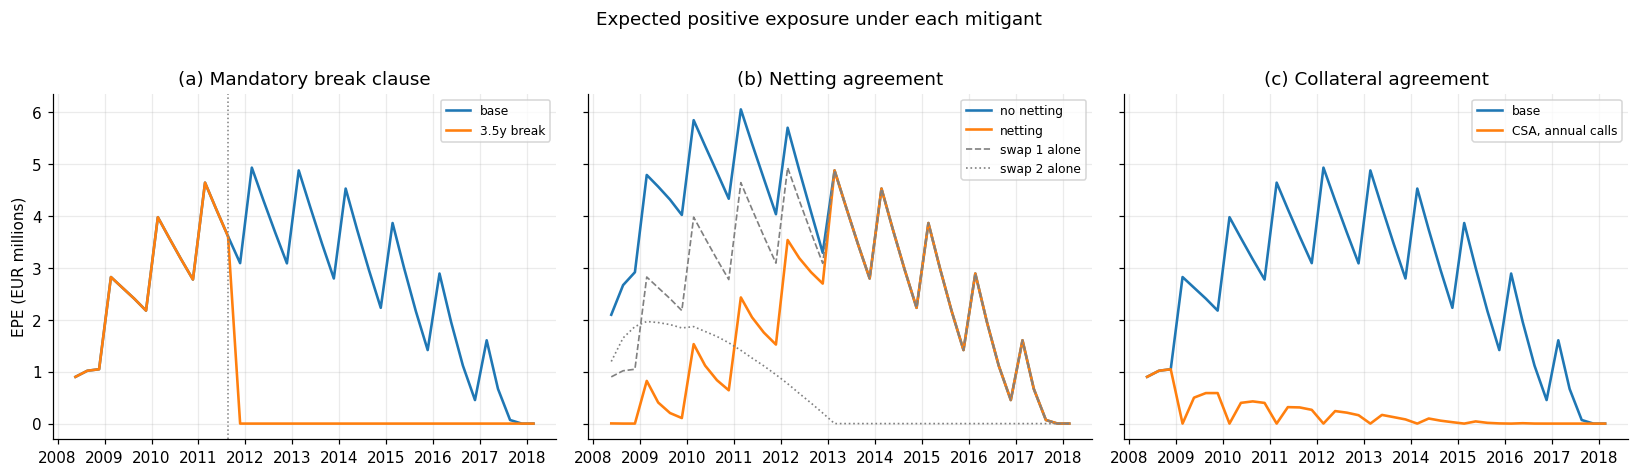

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)

axes[0].plot(results.grid, results.epe["base"] / MILLION, lw=1.7, label="base")
axes[0].plot(results.grid, results.epe["break"] / MILLION, lw=1.7, label="3.5y break")
axes[0].axvline(break_date, color="grey", ls=":", lw=1)
axes[0].set_title("(a) Mandatory break clause")
axes[0].set_ylabel("EPE (EUR millions)")

axes[1].plot(results.grid, results.epe["no_netting"] / MILLION, lw=1.7, label="no netting")
axes[1].plot(results.grid, results.epe["netting"] / MILLION, lw=1.7, label="netting")
axes[1].plot(results.grid, results.epe["base"] / MILLION, lw=1.1, ls="--",
             color="grey", label="swap 1 alone")
axes[1].plot(results.grid, results.epe["swap_2"] / MILLION, lw=1.1, ls=":",
             color="grey", label="swap 2 alone")
axes[1].set_title("(b) Netting agreement")

axes[2].plot(results.grid, results.epe["base"] / MILLION, lw=1.7, label="base")
axes[2].plot(results.grid, results.epe["csa"] / MILLION, lw=1.7, label="CSA, annual calls")
axes[2].set_title("(c) Collateral agreement")

for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Expected positive exposure under each mitigant", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "mitigants_epe.png", bbox_inches="tight")
plt.show()

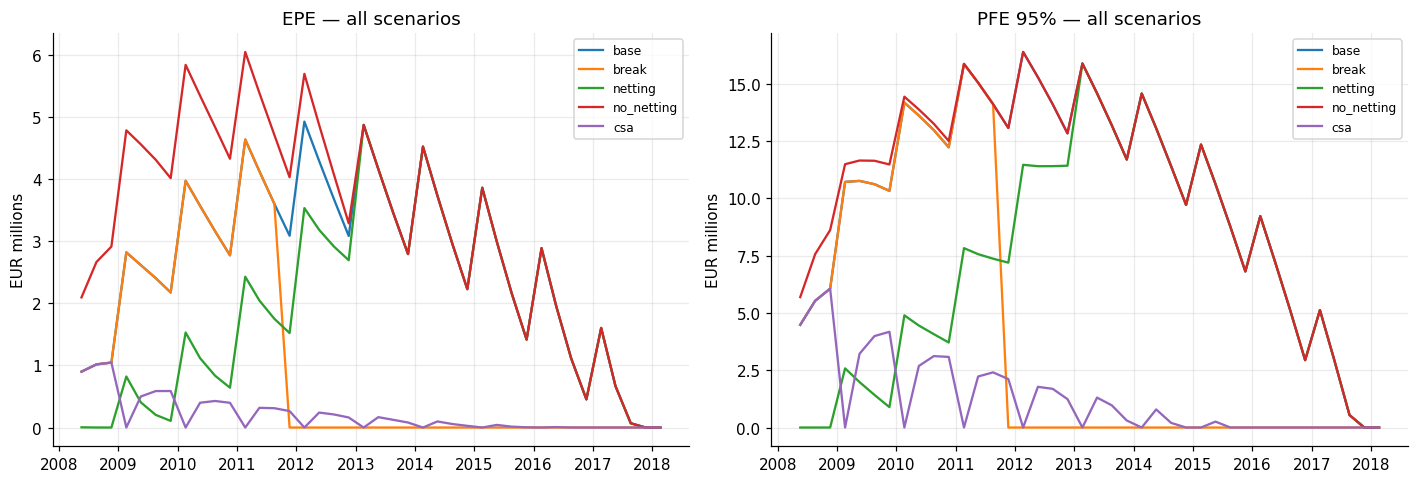

,Max EPE,Peak-PFE,Peak-PFE date,vs base
base,"4,932,168","16,387,755",Feb 2012,+0.0%
break,"4,642,927","15,860,018",Feb 2011,-3.2%
swap_2,"1,967,153","8,519,643",Aug 2009,-48.0%
no_netting,"6,054,716","16,387,755",Feb 2012,+0.0%
netting,"4,878,259","15,883,917",Feb 2013,-3.1%
csa,"1,047,348","6,059,343",Nov 2008,-63.0%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for scenario in ["base", "break", "netting", "no_netting", "csa"]:
    axes[0].plot(results.grid, results.epe[scenario] / MILLION, lw=1.5, label=scenario)
    axes[1].plot(results.grid, results.pfe[scenario] / MILLION, lw=1.5, label=scenario)
axes[0].set_title("EPE — all scenarios")
axes[1].set_title("PFE 95% — all scenarios")
for ax in axes:
    ax.set_ylabel("EUR millions")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "all_scenarios.png", bbox_inches="tight")
plt.show()

summary = pd.DataFrame({
    "Max EPE": results.epe.max(),
    "Peak-PFE": results.pfe.max(),
    "Peak-PFE date": results.pfe.idxmax().dt.strftime("%b %Y"),
})
summary["vs base"] = (summary["Peak-PFE"] / summary.loc["base", "Peak-PFE"] - 1)
display(summary.style.format({"Max EPE": "{:,.0f}", "Peak-PFE": "{:,.0f}", "vs base": "{:+.1%}"}))

**Reading the table.**

*Break clause.* Terminating at 3.5y removes every exposure beyond the break date. Because
the profile of a 10y par swap peaks around year three, the Peak-PFE itself barely moves —
the mitigant cuts the tail of the profile, not its maximum. That is exactly why a mandatory
break is valued for capital relief (it shortens the effective maturity) rather than for
peak exposure.

*Netting.* The positive part is sub-additive, $\max(a+b,0)\le\max(a,0)+\max(b,0)$, so
netting can only reduce exposure — and here the two trades point in opposite directions
(payer versus receiver), so the offset is large over the first five years. After the 5y
swap expires the netted profile collapses back onto the standalone 10y one.

Note that the *PFE* without netting coincides exactly with the PFE of the 10y swap alone,
while the EPE does not. In a one-factor model the two trades are perfectly
anti-correlated: the scenarios that put the payer swap in the 95th percentile are exactly
those where the receiver swap is deeply out of the money, contributing nothing to the sum
of the positive parts. The averaging in the EPE, by contrast, picks up the scenarios where
the receiver swap is in the money. It is a useful reminder that a tail metric and a mean
metric can respond to a change of netting set in completely different ways.

*CSA.* Collateral drives the exposure to zero *at* each posting date, but not between
them: with annual margin calls the residual exposure is the gap risk accumulated over one
year. This is the mechanism that motivates daily margining.

## 5. CVA (question 7)

Under constant LGD, a flat hazard rate and independence between exposure and default,

$$\mathrm{CVA}(0) = \mathrm{LGD}\sum_i \mathrm{EPE}(t_i)\,B(0,t_i)\,\big[S(t_{i-1})-S(t_i)\big],
\qquad S(t) = e^{-\lambda t}$$

with $\lambda = 200$ bp and LGD $= 60\%$. Independence is the assumption that hurts: it
rules out wrong-way risk.

,CVA (EUR),bp of notional,reduction vs base
base,"244,139",24.41,+0.0%
break,"102,760",10.28,+57.9%
no_netting,"313,548",31.35,-28.4%
netting,"159,661",15.97,+34.6%
csa,"21,344",2.13,+91.3%


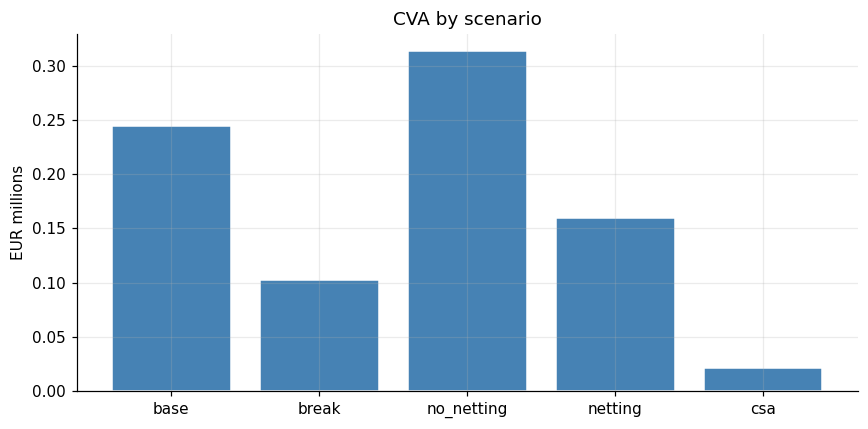

In [11]:
credit = CreditParameters(hazard_rate=0.02, lgd=0.6)

cva = pd.Series(
    {scenario: compute_cva(results.epe[scenario], curve, credit, settlement_date)
     for scenario in ["base", "break", "no_netting", "netting", "csa"]},
    name="CVA (EUR)",
).to_frame()
cva["bp of notional"] = cva["CVA (EUR)"] / swap.notional * 1e4
cva["reduction vs base"] = 1 - cva["CVA (EUR)"] / cva.loc["base", "CVA (EUR)"]
display(cva.style.format({"CVA (EUR)": "{:,.0f}", "bp of notional": "{:.2f}",
                          "reduction vs base": "{:+.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cva.index, cva["CVA (EUR)"] / MILLION, color="steelblue", edgecolor="white")
ax.set_title("CVA by scenario")
ax.set_ylabel("EUR millions")
fig.tight_layout()
fig.savefig(FIGURES / "cva.png", bbox_inches="tight")
plt.show()

### Sensitivities

The three risk factors that actually move the CVA of this position are the level of
interest rates, the credit quality of the counterparty, and the volatility used to
generate the exposure. Each sensitivity is computed by **full revaluation** — the exposure
profile is re-simulated under the bumped input — with the same seed across runs, so the
reported differences are not contaminated by Monte Carlo noise.

Re-discounting a frozen EPE profile, the shortcut, would understate the rate sensitivity
by an order of magnitude: a parallel shift moves the mark-to-market of the swap itself,
hence the whole exposure profile.

In [12]:
sensitivity_config = SimulationConfig(n_scenarios=250_000, seed=config.seed)

sensitivities = cva_sensitivities(
    curve_builder=source.build, curve=curve, swap=swap, swap_netting=swap_2,
    break_date=break_date, csa=csa, hw_params=hw, credit=credit,
    config=sensitivity_config, scenario="base",
)
display(sensitivities.style.format({"bump": "{:.1e}", "cva": "{:,.0f}", "delta_cva": "{:+,.0f}"}))

,bump,cva,delta_cva
risk_factor,,,
base,nan,"244,139",+0
IR01 (+1 bp parallel),1.0e-04,"245,943","+1,804"
CS01 (+1 bp hazard rate),1.0e-04,"245,258","+1,119"
Vega (+1 bp of sigma),1.0e-04,"246,860","+2,720"


**Signs.**

*IR01 > 0.* The position is a payer swap: higher rates make it more valuable, so a
parallel shift raises the expected positive exposure and therefore the CVA. A receiver
swap would show the opposite sign — CVA is directional.

*CS01 > 0.* A wider hazard rate raises the marginal default probabilities directly, with
the exposure unchanged. This is the dominant sensitivity and the one hedged with CDS.

*Vega > 0.* The exposure is the positive part of the mark-to-market, i.e. an option-like
payoff: more volatility means a fatter right tail and a larger EPE. CVA is long
volatility, which is why it is hedged with swaptions and why the calibration of $\sigma$
matters as much as the curve.

## 6. Summary

| Question | Result |
|---|---|
| 3–5, uncollateralised | see the Peak-PFE table above |
| 6a, mandatory 3.5y break | exposure removed beyond 3.5y; Peak-PFE nearly unchanged |
| 6b, netting with the 5y receiver | large offset over the first five years |
| 6c, one-sided CSA, annual calls | exposure reduced to one year of gap risk |
| 7, CVA | falls in line with the exposure reduction of each mitigant |

Every figure in this notebook is reproducible: the simulation is seeded, and the
invariants the results rest on — par repricing of the curve, zero value at inception,
sub-additivity of netting, the affine coefficients against their numerical integral — are
enforced by the test suite in `tests/`.